In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/manish8101/cricket-match-dataset/Cricket_Match_Dataset.xlsx


In [2]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:

# Find the uploaded Excel file in Kaggle Input
files = glob.glob(
    "/kaggle/input/datasets/manish8101/cricket-match-dataset/Cricket_Match_Dataset.xlsx",
    recursive=True
)

if not files:
    raise FileNotFoundError(
        "Cricket_Match_Dataset.xlsx not found. "
        "Please attach your dataset to the Kaggle notebook."
    )

FILE_PATH = files[0]

print("Dataset location:", FILE_PATH)

# Read all three sheets
batting_raw = pd.read_excel(FILE_PATH, sheet_name="Batting")
teambat_raw = pd.read_excel(FILE_PATH, sheet_name="TeamBat")
bowling_raw = pd.read_excel(FILE_PATH, sheet_name="Bowling")

print("\nDataset loaded successfully!")

print("Batting Shape:", batting_raw.shape)
print("TeamBat Shape:", teambat_raw.shape)
print("Bowling Shape:", bowling_raw.shape)

Dataset location: /kaggle/input/datasets/manish8101/cricket-match-dataset/Cricket_Match_Dataset.xlsx

Dataset loaded successfully!
Batting Shape: (745, 15)
TeamBat Shape: (835, 14)
Bowling Shape: (566, 16)


`EDA - Part`

In [4]:
datasets = {
    "Batting": batting_raw,
    "TeamBat": teambat_raw,
    "Bowling": bowling_raw
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(f"DATASET: {name}")
    print("=" * 60)

    print("\nShape:")
    print(df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\nFirst 5 Records:")
    display(df.head())


DATASET: Batting

Shape:
(745, 15)

Column Names:
['Date', 'Team', 'Vs', 'Player', 'Dismissal', 'R', 'B', 'M', '4s', '6s', 'SR', 'Chase', 'Win', 'BoundaryRate', 'RunMint']

Data Types:
Date             object
Team             object
Vs               object
Player           object
Dismissal        object
R                 int64
B                 int64
M                 int64
4s                int64
6s                int64
SR               object
Chase             int64
Win               int64
BoundaryRate    float64
RunMint         float64
dtype: object

Missing Values:
Date              0
Team              0
Vs                0
Player            0
Dismissal         0
R                 0
B                 0
M                 0
4s                0
6s                0
SR                0
Chase             0
Win               0
BoundaryRate    700
RunMint         708
dtype: int64

Duplicate Rows:
0

First 5 Records:


,Date,Team,Vs,Player,Dismissal,R,B,M,4s,6s,SR,Chase,Win,BoundaryRate,RunMint
0,7.2.26,Netherland,Pakistan,Michael Levitt,c Afridi b Nawaz,24,15,23,3,1,160,0,0,NaN,NaN
1,7.2.26,Netherland,Pakistan,Max O'Dowd,c †Usman b Mirza,5,7,16,1,0,71.42,0,0,NaN,NaN
2,7.2.26,Netherland,Pakistan,Bas de Leede,c Babar b Nawaz,30,25,42,4,0,120,0,0,NaN,NaN
3,7.2.26,Netherland,Pakistan,Colin Ackermann,b Abrar Ahmed,20,14,16,4,0,142.85,0,0,NaN,NaN
4,7.2.26,Netherland,Pakistan,Scott Edwards (c)†,c Farhan b Abrar,37,29,32,3,1,127.58,0,0,NaN,NaN



DATASET: TeamBat

Shape:
(835, 14)

Column Names:
['Date', 'Team', 'Vs', 'Player', 'Dismissal', 'R', 'B', 'M', '4s', '6s', 'SR', 'Chase', 'Total', 'Win']

Data Types:
Date          object
Team          object
Vs            object
Player        object
Dismissal     object
R            float64
B            float64
M            float64
4s           float64
6s           float64
SR            object
Chase        float64
Total        float64
Win          float64
dtype: object

Missing Values:
Date          0
Team          0
Vs           90
Player       90
Dismissal    90
R             0
B             0
M             0
4s            0
6s            0
SR            0
Chase         0
Total         0
Win           0
dtype: int64

Duplicate Rows:
0

First 5 Records:


,Date,Team,Vs,Player,Dismissal,R,B,M,4s,6s,SR,Chase,Total,Win
0,7.2.26,Netherland,Pakistan,Michael Levitt,c Afridi b Nawaz,24.0,15.0,23.0,3.0,1.0,160,0.0,147.0,0.0
1,7.2.26,Netherland,Pakistan,Max O'Dowd,c †Usman b Mirza,5.0,7.0,16.0,1.0,0.0,71.42,0.0,147.0,0.0
2,7.2.26,Netherland,Pakistan,Bas de Leede,c Babar b Nawaz,30.0,25.0,42.0,4.0,0.0,120,0.0,147.0,0.0
3,7.2.26,Netherland,Pakistan,Colin Ackermann,b Abrar Ahmed,20.0,14.0,16.0,4.0,0.0,142.85,0.0,147.0,0.0
4,7.2.26,Netherland,Pakistan,Scott Edwards (c)†,c Farhan b Abrar,37.0,29.0,32.0,3.0,1.0,127.58,0.0,147.0,0.0



DATASET: Bowling

Shape:
(566, 16)

Column Names:
['Date', 'Team', 'Vs', 'Bowler', 'O', 'M', 'R', 'W', 'Econ', 'Dots', '4s', '6s', 'Wide', 'NB', 'Win', 'Potential']

Data Types:
Date          object
Team          object
Vs            object
Bowler        object
O             object
M             object
R             object
W             object
Econ          object
Dots          object
4s            object
6s            object
Wide           int64
NB             int64
Win            int64
Potential    float64
dtype: object

Missing Values:
Date           0
Team           0
Vs             2
Bowler         2
O              0
M              0
R              0
W              0
Econ           0
Dots           0
4s             0
6s            11
Wide           0
NB             0
Win            0
Potential    529
dtype: int64

Duplicate Rows:
0

First 5 Records:


,Date,Team,Vs,Bowler,O,M,R,W,Econ,Dots,4s,6s,Wide,NB,Win,Potential
0,7.2.26,Pakistan,Netherland,Shaheen Shah Afridi,3,0,28,1,9.33,8,0,0,0,0,1,NaN
1,7.2.26,Pakistan,Netherland,Salman Mirza,3.5,0,24,3,6.26,14,2,0,2,0,1,NaN
2,7.2.26,Pakistan,Netherland,Mohammad Nawaz,4,0,38,2,9.5,6,0,0,0,0,1,NaN
3,7.2.26,Pakistan,Netherland,Shadab Khan,4,0,26,0,6.5,6,0,0,0,0,1,NaN
4,7.2.26,Pakistan,Netherland,Abrar Ahmed,4,0,23,2,5.75,8,0,0,0,0,1,NaN


`Data Cleaning`

In [5]:
# ==========================================
# 4. CREATE CLEAN COPIES
# ==========================================

batting = batting_raw.copy()
teambat = teambat_raw.copy()
bowling = bowling_raw.copy()


# ==========================================
# 5. STANDARDIZE DATE FORMAT
# ==========================================

def clean_dates(df):

    df["Date"] = pd.to_datetime(
        df["Date"].astype(str).str.strip(),
        format="%d.%m.%y",
        errors="coerce"
    )

    # Fallback for any unexpected date formats
    missing = df["Date"].isna()

    if missing.any():
        df.loc[missing, "Date"] = pd.to_datetime(
            df.loc[missing, "Date"].astype(str),
            dayfirst=True,
            errors="coerce"
        )

    return df


batting = clean_dates(batting)
teambat = clean_dates(teambat)
bowling = clean_dates(bowling)


# ==========================================
# 6. REMOVE EXACT DUPLICATES
# ==========================================

batting = batting.drop_duplicates().copy()
teambat = teambat.drop_duplicates().copy()
bowling = bowling.drop_duplicates().copy()


# ==========================================
# 7. CONVERT NUMERIC COLUMNS
# ==========================================

batting_numeric = [
    "R", "B", "M", "4s", "6s", "SR",
    "Chase", "Win"
]

teambat_numeric = [
    "R", "B", "M", "4s", "6s", "SR",
    "Chase", "Total", "Win"
]

bowling_numeric = [
    "M", "R", "W", "Econ", "Dots",
    "4s", "6s", "Wide", "NB", "Win"
]


for col in batting_numeric:
    batting[col] = pd.to_numeric(
        batting[col], errors="coerce"
    )

for col in teambat_numeric:
    teambat[col] = pd.to_numeric(
        teambat[col], errors="coerce"
    )

for col in bowling_numeric:
    bowling[col] = pd.to_numeric(
        bowling[col], errors="coerce"
    )


# ==========================================
# 8. HANDLE MISSING VALUES
# ==========================================

# Remove records without player information
batting = batting.dropna(
    subset=["Player", "Team", "Date"]
).copy()

# TeamBat contains team summary rows.
# Preserve those separately instead of deleting them.
team_summary = teambat[
    teambat["Player"].isna()
].copy()

# Keep only individual player records in teambat
teambat = teambat[
    teambat["Player"].notna()
].copy()

# Remove invalid bowling records
bowling = bowling.dropna(
    subset=["Bowler", "Team", "Date"]
).copy()

# Missing bowling boundary counts mean no recorded count
bowling[["4s", "6s"]] = bowling[
    ["4s", "6s"]
].fillna(0)

# Fill missing numerical values with zero where appropriate
for df in [batting, teambat]:
    df[["R", "B", "M", "4s", "6s"]] = df[
        ["R", "B", "M", "4s", "6s"]
    ].fillna(0)

# Standardize names and text columns
for df, columns in [
    (batting, ["Team", "Vs", "Player"]),
    (teambat, ["Team", "Player"]),
    (bowling, ["Team", "Vs", "Bowler"])
]:
    for col in columns:
        df[col] = df[col].astype(str).str.strip()


# ==========================================
# 9. CALCULATE MISSING BATTING METRICS
# ==========================================

batting["SR"] = np.where(
    batting["B"] > 0,
    batting["R"] / batting["B"] * 100,
    0
)

batting["BoundaryRuns"] = (
    batting["4s"] * 4 +
    batting["6s"] * 6
)

batting["BoundaryRate"] = np.where(
    batting["R"] > 0,
    batting["BoundaryRuns"] / batting["R"] * 100,
    0
)

batting["RunMint"] = np.where(
    batting["M"] > 0,
    batting["R"] / batting["M"],
    0
)


print("Data cleaning completed!")

print("\nCleaned Dataset Shapes:")
print("Batting:", batting.shape)
print("TeamBat Player Records:", teambat.shape)
print("Team Summary Records:", team_summary.shape)
print("Bowling:", bowling.shape)

print("\nRemaining Missing Values:")

for name, df in [
    ("Batting", batting),
    ("TeamBat", teambat),
    ("Bowling", bowling)
]:
    print(f"\n{name}")
    print(df.isnull().sum())

Data cleaning completed!

Cleaned Dataset Shapes:
Batting: (745, 16)
TeamBat Player Records: (745, 14)
Team Summary Records: (90, 14)
Bowling: (564, 16)

Remaining Missing Values:

Batting
Date            0
Team            0
Vs              0
Player          0
Dismissal       0
R               0
B               0
M               0
4s              0
6s              0
SR              0
Chase           0
Win             0
BoundaryRate    0
RunMint         0
BoundaryRuns    0
dtype: int64

TeamBat
Date         0
Team         0
Vs           0
Player       0
Dismissal    0
R            0
B            0
M            0
4s           0
6s           0
SR           6
Chase        0
Total        0
Win          0
dtype: int64

Bowling
Date           0
Team           0
Vs             0
Bowler         0
O              0
M              1
R              1
W              1
Econ           1
Dots           1
4s             0
6s             0
Wide           0
NB             0
Win            0
Potential    5

`Coreect Bowling Over Calculation`

In [6]:
# ==========================================
# 10. CLEAN BOWLING OVERS AND CONVERT TO BALLS
# ==========================================

# Step 1: Remove repeated header rows
bowling["O"] = bowling["O"].astype(str).str.strip()

bowling = bowling[
    bowling["O"].str.upper() != "O"
].copy()

# Remove rows containing repeated column headers
bowling = bowling[
    bowling["Bowler"].astype(str).str.strip().str.upper()
    != "BOWLER"
].copy()


# Step 2: Convert cricket overs into legal balls

def overs_to_balls(value):

    if pd.isna(value):
        return 0

    value = str(value).strip()

    if value.upper() in ["O", "NAN", "", "NONE"]:
        return 0

    try:
        if "." in value:

            parts = value.split(".")

            overs = int(parts[0])
            balls = int(parts[1])

            if balls < 0 or balls > 5:
                raise ValueError(
                    f"Invalid cricket overs value: {value}"
                )

            return overs * 6 + balls

        return int(float(value)) * 6

    except (ValueError, TypeError):
        return np.nan


bowling["OversBalls"] = bowling["O"].apply(
    overs_to_balls
)

# Step 3: Check invalid values
invalid_overs = bowling[
    bowling["OversBalls"].isna()
]

print("Invalid overs records:", len(invalid_overs))

# Remove invalid overs records from bowling analysis
bowling = bowling.dropna(
    subset=["OversBalls"]
).copy()

bowling["OversBalls"] = bowling["OversBalls"].astype(int)


# Step 4: Recalculate economy rate

bowling["CalculatedEcon"] = np.where(

    bowling["OversBalls"] > 0,

    bowling["R"] / (bowling["OversBalls"] / 6),

    0

)


# Step 5: Display results

print("Bowling overs converted successfully!")

display(
    bowling[
        [
            "Bowler",
            "O",
            "OversBalls",
            "R",
            "W",
            "CalculatedEcon"
        ]
    ].head(15)
)

Invalid overs records: 0
Bowling overs converted successfully!


,Bowler,O,OversBalls,R,W,CalculatedEcon
0,Shaheen Shah Afridi,3,18,28.0,1.0,9.333333
1,Salman Mirza,3.5,23,24.0,3.0,6.260870
2,Mohammad Nawaz,4,24,38.0,2.0,9.500000
3,Shadab Khan,4,24,26.0,0.0,6.500000
4,Abrar Ahmed,4,24,23.0,2.0,5.750000
5,Saim Ayub,1,6,7.0,2.0,7.000000
7,Aryan Dutt,4,24,33.0,2.0,8.250000
8,Logan van Beek,4,24,46.0,1.0,11.500000
9,Kyle Klein,3,18,23.0,1.0,7.666667
10,Roelof van der Merwe,3,18,13.0,1.0,4.333333


`Create match identifiers and team innings dataset`

In [7]:

# ==========================================
# 11. CREATE MATCH ID
# ==========================================

def create_match_id(df):

    df = df.copy()

    # Handle missing opponent column
    if "Vs" not in df.columns:

        if "Vs_x" in df.columns:
            df["Vs"] = df["Vs_x"]

        elif "Vs_y" in df.columns:
            df["Vs"] = df["Vs_y"]

        else:
            raise ValueError(
                "Opponent column Vs not found. Check dataset columns."
            )

    teams = df[["Team", "Vs"]].fillna("Unknown").astype(str).apply(
        lambda row: sorted(row.tolist()),
        axis=1
    )

    return (
        df["Date"].dt.strftime("%Y-%m-%d") +
        "_" +
        teams.apply(lambda x: "_".join(x))
    )


batting["MatchID"] = create_match_id(batting)

bowling["MatchID"] = create_match_id(bowling)


# ==========================================
# 12. PREPARE TEAM INNINGS DATA
# ==========================================

# Extract team and opponent information
team_metadata = batting[
    ["Date", "Team", "Vs"]
].drop_duplicates(
    subset=["Date", "Team"]
)


# Remove existing opponent column to avoid Vs_x / Vs_y
team_summary_clean = team_summary.drop(
    columns=["Vs", "Vs_x", "Vs_y"],
    errors="ignore"
)


# Merge team summary with opponent information
team_innings = team_summary_clean.merge(
    team_metadata,
    on=["Date", "Team"],
    how="left"
)


# Create MatchID
team_innings["MatchID"] = create_match_id(team_innings)


# Convert numerical columns
for col in ["Total", "Chase", "Win"]:

    team_innings[col] = pd.to_numeric(
        team_innings[col],
        errors="coerce"
    )


team_innings["Chase"] = team_innings["Chase"].fillna(0)

team_innings["Win"] = team_innings["Win"].fillna(0).astype(int)


# Display results
print("Team innings dataset created successfully!")

display(team_innings.head(10))

print("\nTotal Team Innings:", len(team_innings))

print(
    "Total Matches:",
    team_innings["MatchID"].nunique()
)

print("\nFinal Columns:")
print(team_innings.columns.tolist())


Team innings dataset created successfully!


,Date,Team,Player,Dismissal,R,B,M,4s,6s,SR,Chase,Total,Win,Vs,MatchID
0,2026-02-07,Netherland,NaN,NaN,13.090909,10.818182,16.272727,1.636364,0.181818,94.662727,0.0,147.0,0,Pakistan,2026-02-07_Netherland_Pakistan
1,2026-02-07,Pakistan,NaN,NaN,16.222222,13.000000,21.555556,1.555556,0.666667,111.282222,1.0,148.0,1,Netherland,2026-02-07_Netherland_Pakistan
2,2026-02-07,West Indies,NaN,NaN,25.000000,17.142857,27.571429,1.857143,1.571429,143.172857,0.0,182.0,1,Scotland,2026-02-07_Scotland_West Indies
3,2026-02-07,Scotland,NaN,NaN,12.636364,10.363636,17.727273,1.000000,0.454545,77.725455,1.0,147.0,0,West Indies,2026-02-07_Scotland_West Indies
4,2026-02-07,India,NaN,NaN,15.800000,12.000000,20.700000,1.800000,0.700000,85.864444,1.0,161.0,1,USA,2026-02-07_India_USA
5,2026-02-07,USA,NaN,NaN,14.000000,13.333333,21.000000,0.777778,0.777778,67.960000,0.0,132.0,0,India,2026-02-07_India_USA
6,2026-02-08,Afganisthan,NaN,NaN,24.714286,17.142857,27.857143,1.285714,1.285714,143.367143,0.0,182.0,0,New Zealand,2026-02-08_Afganisthan_New Zealand
7,2026-02-08,New Zealand,NaN,NaN,25.428571,15.571429,25.285714,2.714286,1.000000,132.647143,1.0,183.0,1,NaN,2026-02-08_New Zealand _Unknown
8,2026-02-08,Ireland,NaN,NaN,12.454545,10.818182,18.727273,1.090909,0.090909,94.168000,0.0,143.0,0,Sri Lanka,2026-02-08_Ireland_Sri Lanka
9,2026-02-08,Sri Lanka,NaN,NaN,19.250000,15.125000,26.750000,1.500000,0.375000,96.985000,1.0,163.0,1,Ireland,2026-02-08_Ireland_Sri Lanka



Total Team Innings: 90
Total Matches: 57

Final Columns:
['Date', 'Team', 'Player', 'Dismissal', 'R', 'B', 'M', '4s', '6s', 'SR', 'Chase', 'Total', 'Win', 'Vs', 'MatchID']


`SOLVED 10 QUESTIONS`

# 1. Who are the top 10 batsmen based on their total runs scored across all matches? 

In [8]:
player_batting = batting.groupby("Player").agg(

    Matches=("MatchID", "nunique"),
    Innings=("R", "count"),
    Total_Runs=("R", "sum"),
    Balls_Faced=("B", "sum"),
    Fours=("4s", "sum"),
    Sixes=("6s", "sum")

).reset_index()

# Calculate overall strike rate
player_batting["Strike_Rate"] = np.where(
    player_batting["Balls_Faced"] > 0,
    player_batting["Total_Runs"] /
    player_batting["Balls_Faced"] * 100,
    0
)

# Boundary runs
player_batting["Boundary_Runs"] = (
    player_batting["Fours"] * 4 +
    player_batting["Sixes"] * 6
)

top_10_batsmen = player_batting.sort_values(
    "Total_Runs",
    ascending=False
).head(10)

print("TOP 10 BATSMEN")

display(top_10_batsmen)

TOP 10 BATSMEN


,Player,Matches,Innings,Total_Runs,Balls_Faced,Fours,Sixes,Strike_Rate,Boundary_Runs
227,Sahibzada Farhan,5,5,383,235,37,18,162.978723,256
40,Brian Bennett,5,5,277,204,31,6,135.784314,160
9,Aiden Markram (c),5,5,236,137,26,9,172.262774,158
266,Suryakumar Yadav (c),5,5,231,146,25,11,158.219178,166
254,Shimron Hetmyer,6,6,221,121,15,17,182.644628,162
196,Pathum Nissanka,6,6,207,135,22,6,153.333333,124
199,Pavan Rathnayake,6,6,205,132,20,7,155.303030,122
223,Ryan Rickelton,6,6,197,111,17,11,177.477477,134
71,Finn Allen,6,6,189,109,14,12,173.394495,128
258,Shubham Ranjane,5,5,178,100,11,11,178.000000,110


# 2. Which 10 players have the highest strike rate among players who have faced at least 50 balls?

In [9]:
qualified_players = player_batting[
    player_batting["Balls_Faced"] >= 50
].copy()

top_10_strike_rate = qualified_players.sort_values(
    "Strike_Rate",
    ascending=False
).head(10)

print("TOP 10 STRIKE RATE")

display(
    top_10_strike_rate[
        [
            "Player",
            "Matches",
            "Total_Runs",
            "Balls_Faced",
            "Strike_Rate"
        ]
    ]
)

TOP 10 STRIKE RATE


,Player,Matches,Total_Runs,Balls_Faced,Strike_Rate
173,Mitchell Marsh,2,118,60,196.666667
69,Fakhar Zaman,2,109,58,187.931034
131,KamIndiau Mendis,4,101,54,187.037037
253,Sherfane Rutherford,4,145,78,185.897436
146,LorCanada Tucker (c)†,1,94,51,184.313725
254,Shimron Hetmyer,6,221,121,182.644628
30,Ben Manenti,3,138,77,179.220779
258,Shubham Ranjane,5,178,100,178.000000
223,Ryan Rickelton,6,197,111,177.477477
114,Jason Holder,4,104,59,176.271186


# 3. Which player has scored the most fours and which player has scored the most sixes? 

In [10]:
# Player with maximum fours
max_fours = player_batting["Fours"].max()

most_fours = player_batting[
    player_batting["Fours"] == max_fours
][["Player", "Fours"]]

# Player with maximum sixes
max_sixes = player_batting["Sixes"].max()

most_sixes = player_batting[
    player_batting["Sixes"] == max_sixes
][["Player", "Sixes"]]

print("PLAYER WITH MOST FOURS")
display(most_fours)

print("\nPLAYER WITH MOST SIXES")
display(most_sixes)

PLAYER WITH MOST FOURS


,Player,Fours
227,Sahibzada Farhan,37



PLAYER WITH MOST SIXES


,Player,Sixes
227,Sahibzada Farhan,18


# 4. Which team has won the highest number of matches, and how many matches did they win? 

In [11]:
team_results = team_innings[
    ["MatchID", "Team", "Win"]
].drop_duplicates(
    subset=["MatchID", "Team"]
)

team_wins = team_results.groupby("Team").agg(

    Matches_Played=("MatchID", "nunique"),
    Matches_Won=("Win", "sum")

).reset_index()

team_wins = team_wins.sort_values(
    "Matches_Won",
    ascending=False
)

print("TEAM WINS")

display(team_wins.head(10))

print("\nMOST SUCCESSFUL TEAM:")

display(
    team_wins[
        team_wins["Matches_Won"] ==
        team_wins["Matches_Won"].max()
    ]
)

TEAM WINS


,Team,Matches_Played,Matches_Won
17,South Africa,6,6
22,West Indies,6,5
5,India,6,5
15,Pakistan,6,4
18,Sri Lanka,5,3
0,Afganisthan,4,2
1,Australia,4,2
4,England,4,2
21,USA,4,2
24,Zimbabwe,4,2



MOST SUCCESSFUL TEAM:


,Team,Matches_Played,Matches_Won
17,South Africa,6,6


# 5. For each match, who was the highest run scorer? Can you display the player name, team, opponent, match date, and runs scored? 

In [12]:
match_highest_runs = batting.groupby(
    "MatchID"
)["R"].transform("max")

highest_scorers = batting[
    batting["R"] == match_highest_runs
][
    [
        "Date",
        "MatchID",
        "Player",
        "Team",
        "Vs",
        "R"
    ]
].copy()

highest_scorers = highest_scorers.sort_values(
    ["Date", "MatchID"],
    ascending=True
)

highest_scorers = highest_scorers.rename(
    columns={
        "Player": "Highest_Scorer",
        "Vs": "Opponent",
        "R": "Runs_Scored"
    }
)

print("HIGHEST SCORER IN EACH MATCH")

display(highest_scorers)

HIGHEST SCORER IN EACH MATCH


,Date,MatchID,Highest_Scorer,Team,Opponent,Runs_Scored
41,2026-02-07,2026-02-07_India_USA,Suryakumar Yadav (c),India,USA,84
11,2026-02-07,2026-02-07_Netherland_Pakistan,Sahibzada Farhan,Pakistan,Netherland,47
20,2026-02-07,2026-02-07_Scotland_West Indies,Shimron Hetmyer,West Indies,Scotland,64
64,2026-02-08,2026-02-08_Afganistan_New Zealand,Tim Seifert †,New Zealand,Afganistan,65
59,2026-02-08,2026-02-08_Afganisthan_New Zealand,Gulbadin Naib,Afganisthan,New Zealand,63
84,2026-02-08,2026-02-08_Ireland_Sri Lanka,Kusal Mendis †,Sri Lanka,Ireland,56
98,2026-02-09,2026-02-09_Canada_South Africa,Navneet Dhaliwal,Canada,South Africa,64
122,2026-02-09,2026-02-09_Italy_Scotland,George Munsey,Scotland,Italy,84
117,2026-02-09,2026-02-09_Oman_Zimbabwe,Brian Bennett,Zimbabwe,Oman,48
112,2026-02-09,2026-02-09_Oman_Zimbawe,Vinayak Shukla †,Oman,Zimbawe,28


# 6. Do teams perform better while chasing or while batting first? Compare their average runs and overall performance in both situations.

In [13]:
team_innings["Batting_Type"] = team_innings[
    "Chase"
].map({
    0: "Batting First",
    1: "Chasing"
})

chase_analysis = team_innings.groupby(
    "Batting_Type"
).agg(

    Total_Innings=("MatchID", "count"),
    Average_Runs=("Total", "mean"),
    Total_Runs=("Total", "sum"),
    Matches_Won=("Win", "sum"),
    Win_Percentage=("Win", "mean")

).reset_index()

chase_analysis["Win_Percentage"] *= 100

print("CHASING VS BATTING FIRST")

display(chase_analysis)

# Determine better performing situation
best_situation = chase_analysis.sort_values(
    ["Win_Percentage", "Average_Runs"],
    ascending=False
).iloc[0]

print("\nBETTER PERFORMING SITUATION:")
print(best_situation["Batting_Type"])

print("Win Percentage:",
      round(best_situation["Win_Percentage"], 2), "%")

print("Average Runs:",
      round(best_situation["Average_Runs"], 2))

CHASING VS BATTING FIRST


,Batting_Type,Total_Innings,Average_Runs,Total_Runs,Matches_Won,Win_Percentage
0,Batting First,45,175.022222,7876.0,23,51.111111
1,Chasing,44,151.704545,6675.0,21,47.727273



BETTER PERFORMING SITUATION:
Batting First
Win Percentage: 51.11 %
Average Runs: 175.02


# 7. Who are the top 10 bowlers based on total wickets taken, and what are their average economy rates? 

In [14]:
bowler_performance = bowling.groupby("Bowler").agg(

    Matches=("MatchID", "nunique"),
    Innings=("W", "count"),
    Total_Wickets=("W", "sum"),
    Runs_Conceded=("R", "sum"),
    Total_Balls=("OversBalls", "sum"),
    Average_Innings_Economy=("CalculatedEcon", "mean")

).reset_index()

# Calculate weighted overall economy
bowler_performance["Overall_Economy"] = np.where(
    bowler_performance["Total_Balls"] > 0,
    bowler_performance["Runs_Conceded"] /
    (bowler_performance["Total_Balls"] / 6),
    0
)

top_10_bowlers = bowler_performance.sort_values(
    ["Total_Wickets", "Overall_Economy"],
    ascending=[False, True]
).head(10)

print("TOP 10 BOWLERS")

display(
    top_10_bowlers[
        [
            "Bowler",
            "Matches",
            "Total_Wickets",
            "Runs_Conceded",
            "Overall_Economy",
            "Average_Innings_Economy"
        ]
    ]
)

TOP 10 BOWLERS


,Bowler,Matches,Total_Wickets,Runs_Conceded,Overall_Economy,Average_Innings_Economy
169,Shadley van Schalkwyk,4,13.0,101.0,6.808989,6.852941
109,Lungi Ngidi,5,11.0,136.0,6.800000,6.800000
114,Marco Jansen,5,11.0,184.0,9.277311,9.247826
188,Usman Tariq,5,10.0,141.0,7.230769,7.164286
26,Blessing Muzarabani,4,10.0,118.0,7.375000,7.375000
66,Gudakesh Motie,6,10.0,155.0,7.750000,8.166667
38,Corbin Bosch,5,9.0,116.0,6.105263,6.000000
148,Rachin Ravindra,5,9.0,88.0,6.769231,8.166667
124,Michael Leask,4,9.0,122.0,7.625000,7.625000
5,Adil Rashid,5,9.0,154.0,7.700000,7.700000


# 8. Which players have scored the most runs through boundaries (fours and sixes), and how does their strike rate compare with other players?

In [15]:
boundary_players = player_batting.copy()

# Calculate strike rate ranking
boundary_players["SR_Rank"] = (
    boundary_players["Strike_Rate"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Compare with overall player strike rate
overall_average_sr = (
    player_batting["Total_Runs"].sum() /
    player_batting["Balls_Faced"].sum() * 100
)

boundary_players["SR_vs_Overall"] = (
    boundary_players["Strike_Rate"] -
    overall_average_sr
)

top_boundary_players = boundary_players.sort_values(
    "Boundary_Runs",
    ascending=False
).head(10)

print("TOP 10 BOUNDARY SCORERS")

print(
    "Overall aggregate strike rate:",
    round(overall_average_sr, 2)
)

display(
    top_boundary_players[
        [
            "Player",
            "Total_Runs",
            "Fours",
            "Sixes",
            "Boundary_Runs",
            "Strike_Rate",
            "SR_Rank",
            "SR_vs_Overall"
        ]
    ]
)

TOP 10 BOUNDARY SCORERS
Overall aggregate strike rate: 136.76


,Player,Total_Runs,Fours,Sixes,Boundary_Runs,Strike_Rate,SR_Rank,SR_vs_Overall
227,Sahibzada Farhan,383,37,18,256,162.978723,55,26.223017
266,Suryakumar Yadav (c),231,25,11,166,158.219178,62,21.463471
254,Shimron Hetmyer,221,15,17,162,182.644628,24,45.888921
40,Brian Bennett,277,31,6,160,135.784314,108,-0.971393
9,Aiden Markram (c),236,26,9,158,172.262774,38,35.507067
223,Ryan Rickelton,197,17,11,134,177.477477,30,40.721771
71,Finn Allen,189,14,12,128,173.394495,34,36.638789
278,Tim Seifert †,175,21,7,126,171.568627,39,34.812921
196,Pathum Nissanka,207,22,6,124,153.333333,72,16.577627
199,Pavan Rathnayake,205,20,7,122,155.303030,69,18.547324


# 9. Can you create a Player Performance Score using runs, strike rate, fours, sixes, and balls faced, and use it to rank the top 20 batsmen?

In [16]:
pps = player_batting.copy()

# Calculate percentile scores
pps["Runs_Score"] = (
    pps["Total_Runs"].rank(pct=True) * 100
)

pps["SR_Score"] = (
    pps["Strike_Rate"].rank(pct=True) * 100
)

pps["Fours_Score"] = (
    pps["Fours"].rank(pct=True) * 100
)

pps["Sixes_Score"] = (
    pps["Sixes"].rank(pct=True) * 100
)

pps["Balls_Score"] = (
    pps["Balls_Faced"].rank(pct=True) * 100
)

# Calculate Player Performance Score
pps["PPS"] = (

    0.30 * pps["Runs_Score"] +
    0.25 * pps["SR_Score"] +
    0.15 * pps["Fours_Score"] +
    0.15 * pps["Sixes_Score"] +
    0.15 * pps["Balls_Score"]

)

# Rank players
pps["PPS_Rank"] = pps["PPS"].rank(
    ascending=False,
    method="min"
).astype(int)

top_20_pps = pps.sort_values(
    "PPS",
    ascending=False
).head(20)

print("TOP 20 BATSMEN BY PPS")

display(
    top_20_pps[
        [
            "PPS_Rank",
            "Player",
            "Total_Runs",
            "Strike_Rate",
            "Fours",
            "Sixes",
            "Balls_Faced",
            "PPS"
        ]
    ]
)

TOP 20 BATSMEN BY PPS


,PPS_Rank,Player,Total_Runs,Strike_Rate,Fours,Sixes,Balls_Faced,PPS
254,1,Shimron Hetmyer,221,182.644628,15,17,121,96.644518
9,2,Aiden Markram (c),236,172.262774,26,9,137,95.855482
223,3,Ryan Rickelton,197,177.477477,17,11,111,95.697674
227,4,Sahibzada Farhan,383,162.978723,37,18,235,95.514950
71,5,Finn Allen,189,173.394495,14,12,109,94.867110
258,6,Shubham Ranjane,178,178.000000,11,11,100,94.294020
266,7,Suryakumar Yadav (c),231,158.219178,25,11,146,94.111296
278,8,Tim Seifert †,175,171.568627,21,7,102,93.280731
253,9,Sherfane Rutherford,145,185.897436,9,11,78,92.549834
82,10,Glenn Phillips,176,160.000000,16,8,110,92.250831


# 10. Can you combine the batting and bowling data to identify the top 10 all-round performers? Create your own Match Impact Score using runs, wickets, strike rate, economy rate, boundaries, and match result? 

In [17]:
#1: PLAYER MATCH-WISE BATTING

batting_pm = batting.groupby(
    ["MatchID", "Date", "Team", "Vs", "Player"]
).agg(

    Runs=("R", "sum"),
    Balls_Faced=("B", "sum"),
    Fours=("4s", "sum"),
    Sixes=("6s", "sum"),
    Batting_Win=("Win", "max")

).reset_index()


# 2: PLAYER MATCH-WISE BOWLING
bowling_pm = bowling.groupby(
    ["MatchID", "Date", "Team", "Vs", "Bowler"]
).agg(

    Wickets=("W", "sum"),
    Runs_Conceded=("R", "sum"),
    Bowling_Balls=("OversBalls", "sum"),
    Bowling_Win=("Win", "max")

).reset_index()

# Rename Bowler to Player for merging
bowling_pm = bowling_pm.rename(
    columns={"Bowler": "Player"}
)


# 3: MERGE BATTING AND BOWLING
player_match = pd.merge(

    batting_pm,
    bowling_pm,

    on=[
        "MatchID",
        "Date",
        "Team",
        "Vs",
        "Player"
    ],

    how="outer"
)
# 4: HANDLE MISSING PERFORMANCE VALUES
numeric_cols = [
    "Runs",
    "Balls_Faced",
    "Fours",
    "Sixes",
    "Batting_Win",
    "Wickets",
    "Runs_Conceded",
    "Bowling_Balls",
    "Bowling_Win"
]

player_match[numeric_cols] = player_match[
    numeric_cols
].fillna(0)


#5: CALCULATE MATCH PERFORMANCE
player_match["Match_SR"] = np.where(

    player_match["Balls_Faced"] > 0,

    player_match["Runs"] /
    player_match["Balls_Faced"] * 100,

    np.nan

)

player_match["Match_Economy"] = np.where(

    player_match["Bowling_Balls"] > 0,

    player_match["Runs_Conceded"] /
    (player_match["Bowling_Balls"] / 6),

    np.nan

)

player_match["Boundary_Runs"] = (
    player_match["Fours"] * 4 +
    player_match["Sixes"] * 6
)

# A player gets one match-result observation
player_match["Match_Win"] = player_match[
    ["Batting_Win", "Bowling_Win"]
].max(axis=1)


# 6: AGGREGATE PLAYER PERFORMANCE
allround = player_match.groupby("Player").agg(

    Matches=("MatchID", "nunique"),

    Total_Runs=("Runs", "sum"),

    Total_Wickets=("Wickets", "sum"),

    Balls_Faced=("Balls_Faced", "sum"),

    Total_Fours=("Fours", "sum"),

    Total_Sixes=("Sixes", "sum"),

    Boundary_Runs=("Boundary_Runs", "sum"),

    Runs_Conceded=("Runs_Conceded", "sum"),

    Bowling_Balls=("Bowling_Balls", "sum"),

    Average_Match_SR=("Match_SR", "mean"),

    Average_Innings_Economy=("Match_Economy", "mean"),

    Match_Wins=("Match_Win", "sum")

).reset_index()


# 7: CALCULATE OVERALL STRIKE RATE
allround["Strike_Rate"] = np.where(

    allround["Balls_Faced"] > 0,

    allround["Total_Runs"] /
    allround["Balls_Faced"] * 100,

    0

)


#8: CALCULATE OVERALL ECONOMY RATE
allround["Economy_Rate"] = np.where(

    allround["Bowling_Balls"] > 0,

    allround["Runs_Conceded"] /
    (allround["Bowling_Balls"] / 6),

    np.nan

)
# 9: CALCULATE WIN PERCENTAGE
allround["Win_Percentage"] = (

    allround["Match_Wins"] /
    allround["Matches"].replace(0, np.nan) * 100

).fillna(0)

#10: NORMALIZE PERFORMANCE METRICS
allround["Runs_Score"] = (
    allround["Total_Runs"].rank(pct=True) * 100
)

allround["Wickets_Score"] = (
    allround["Total_Wickets"].rank(pct=True) * 100
)

allround["SR_Score"] = (
    allround["Strike_Rate"].rank(pct=True) * 100
)

# Lower economy rate receives a higher score
allround["Economy_Score"] = (
    allround["Economy_Rate"]
    .rank(pct=True, ascending=False) * 100
).fillna(0)

allround["Boundary_Score"] = (
    allround["Boundary_Runs"].rank(pct=True) * 100
)

allround["Win_Score"] = (
    allround["Win_Percentage"].rank(pct=True) * 100
)


#11: CALCULATE MATCH IMPACT SCORE
allround["MIS"] = (

    0.25 * allround["Runs_Score"] +

    0.25 * allround["Wickets_Score"] +

    0.15 * allround["SR_Score"] +

    0.15 * allround["Economy_Score"] +

    0.10 * allround["Boundary_Score"] +

    0.10 * allround["Win_Score"]

)
#12: RANK ALL-ROUND PERFORMERS
allround["MIS_Rank"] = allround["MIS"].rank(
    ascending=False,
    method="min"
).astype(int)

top_10_allround = allround.sort_values(
    "MIS",
    ascending=False
).head(10)

print("TOP 10 ALL-ROUND PERFORMERS")

display(
    top_10_allround[
        [
            "MIS_Rank",
            "Player",
            "Matches",
            "Total_Runs",
            "Total_Wickets",
            "Strike_Rate",
            "Economy_Rate",
            "Boundary_Runs",
            "Win_Percentage",
            "MIS"
        ]
    ]
)

TOP 10 ALL-ROUND PERFORMERS


,MIS_Rank,Player,Matches,Total_Runs,Total_Wickets,Strike_Rate,Economy_Rate,Boundary_Runs,Win_Percentage,MIS
103,1,Hardik Pandya,7,160.0,5.0,158.415842,8.428571,108.0,85.714286,84.615393
129,2,Jason Holder,7,104.0,8.0,176.271186,8.736842,80.0,85.714286,84.306163
36,3,Ben Manenti,4,138.0,4.0,179.220779,6.600000,92.0,25.000000,84.266598
314,4,Tilak Varma,6,151.0,1.0,158.947368,5.500000,102.0,83.333333,83.729306
86,5,George Dockrell,3,85.0,4.0,188.888889,6.000000,58.0,33.333333,82.778457
295,6,Shubham Ranjane,5,178.0,1.0,178.000000,6.500000,110.0,40.000000,81.489213
250,7,Romario Shepherd,4,80.0,6.0,156.862745,8.166667,60.0,75.000000,79.913686
277,8,Shadab Khan,6,99.0,5.0,165.000000,8.444444,60.0,66.666667,79.885594
28,9,Azmatullah Omarzai,6,76.0,8.0,168.888889,8.112676,50.0,33.333333,79.101690
94,10,Glenn Phillips,7,176.0,3.0,160.000000,9.333333,112.0,71.428571,78.370647


`Visualization`

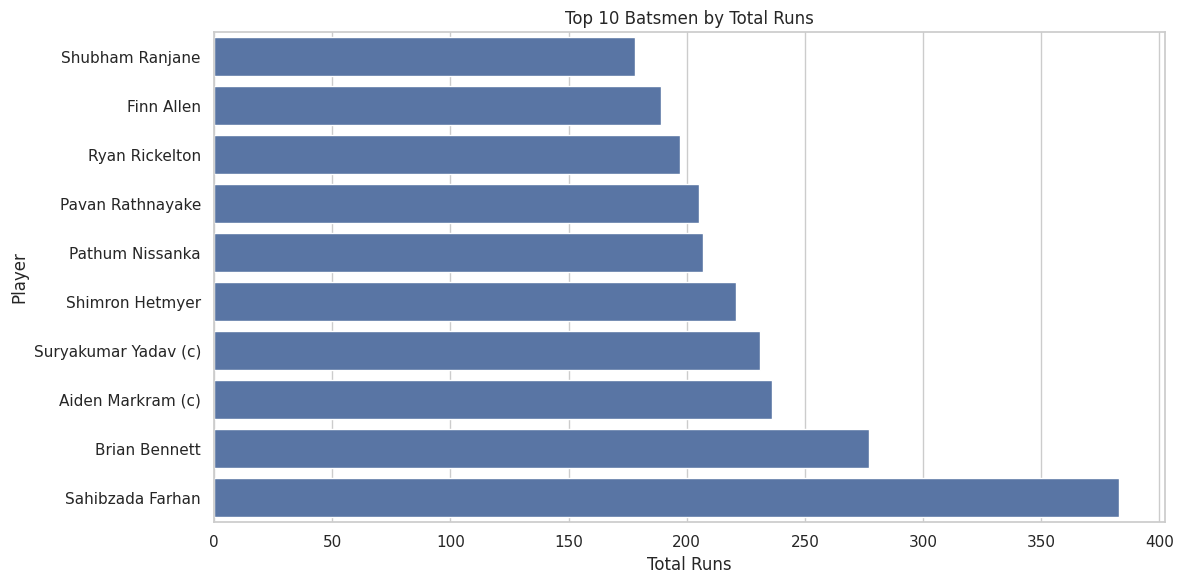

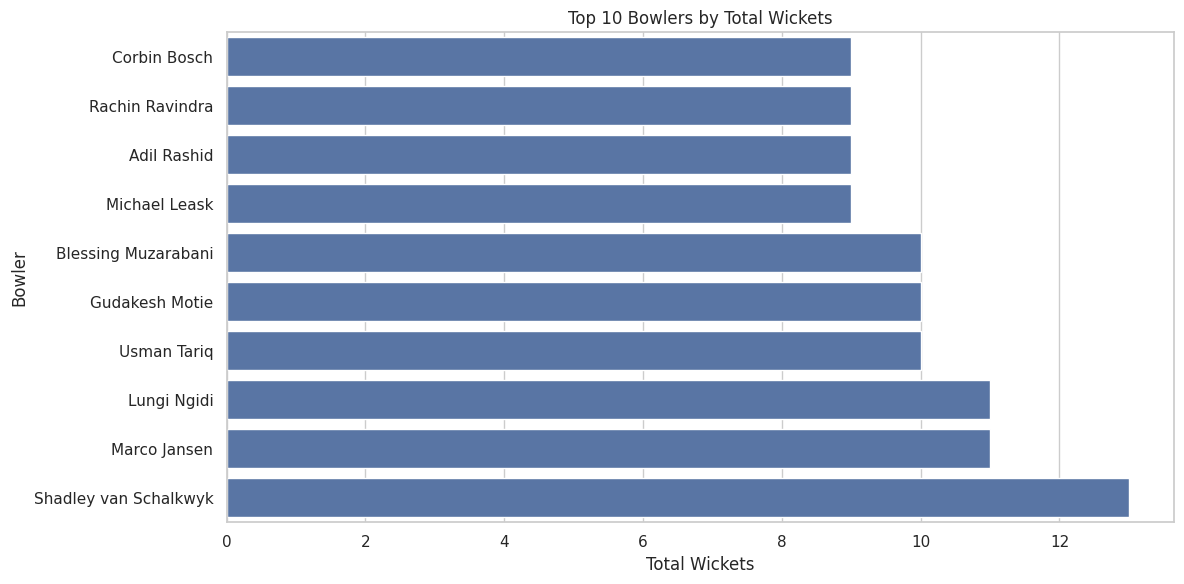

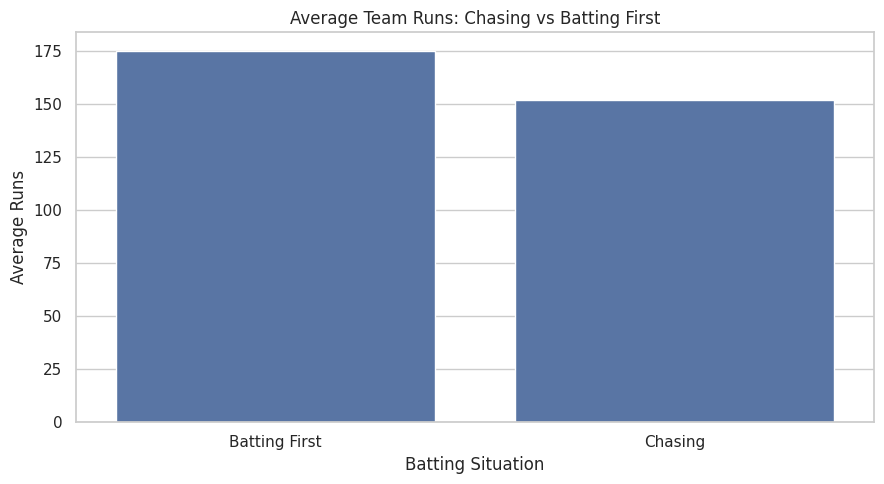

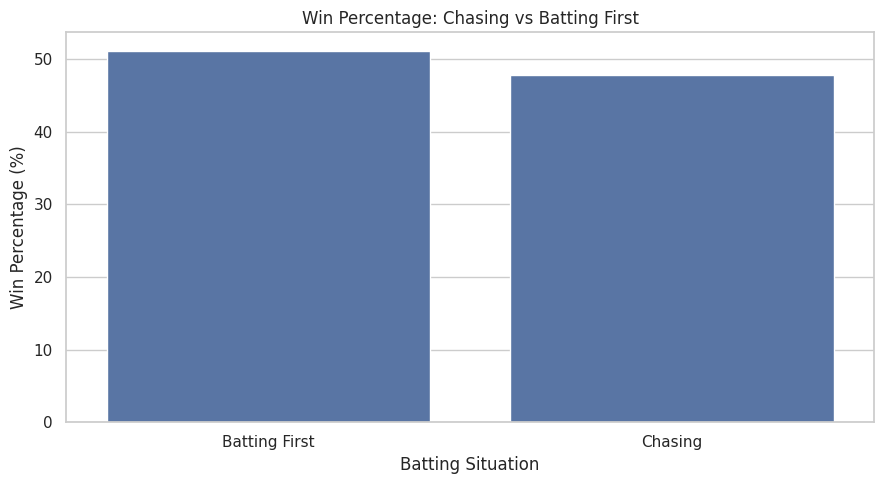

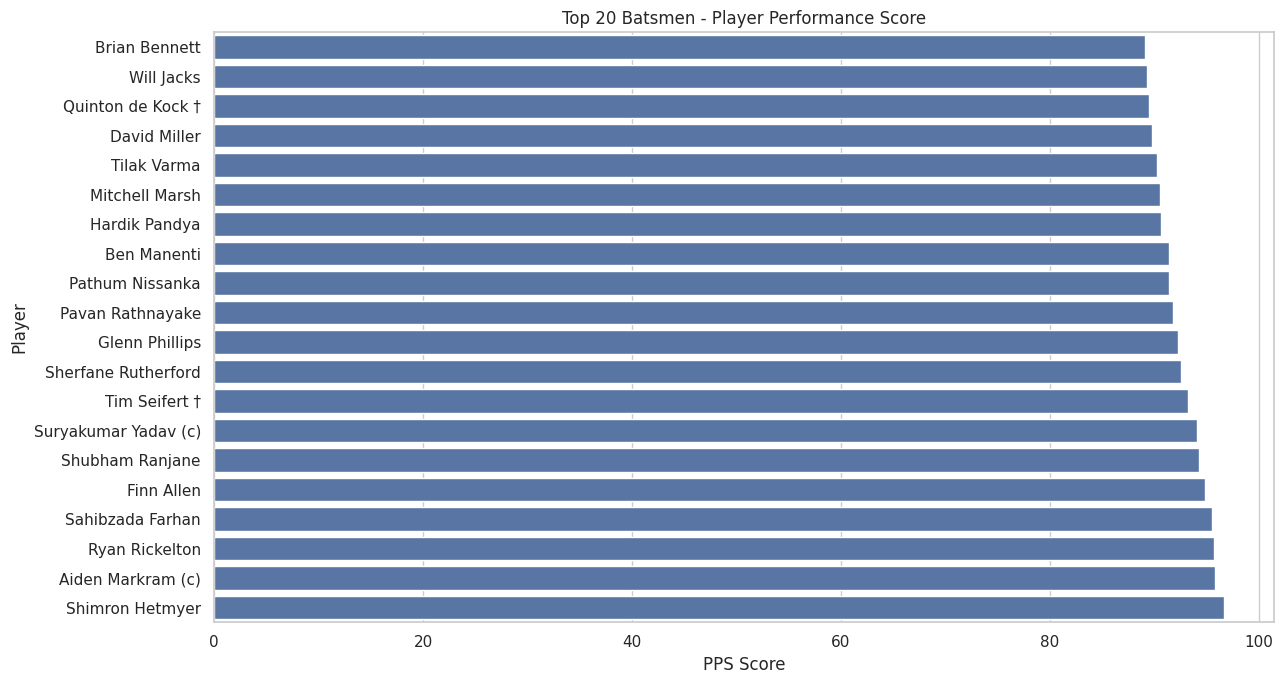

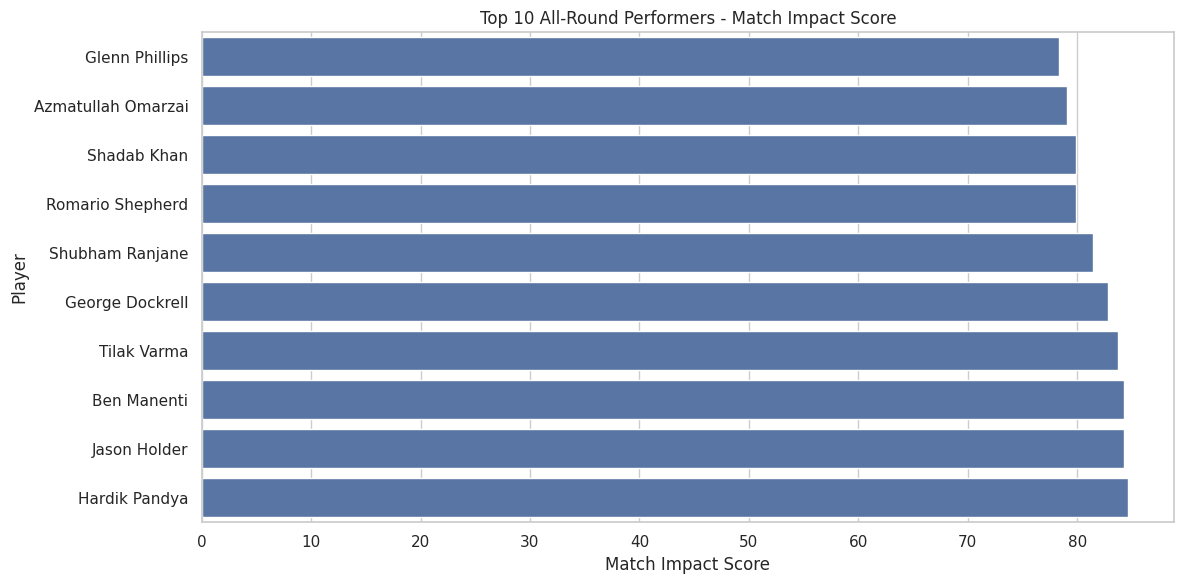

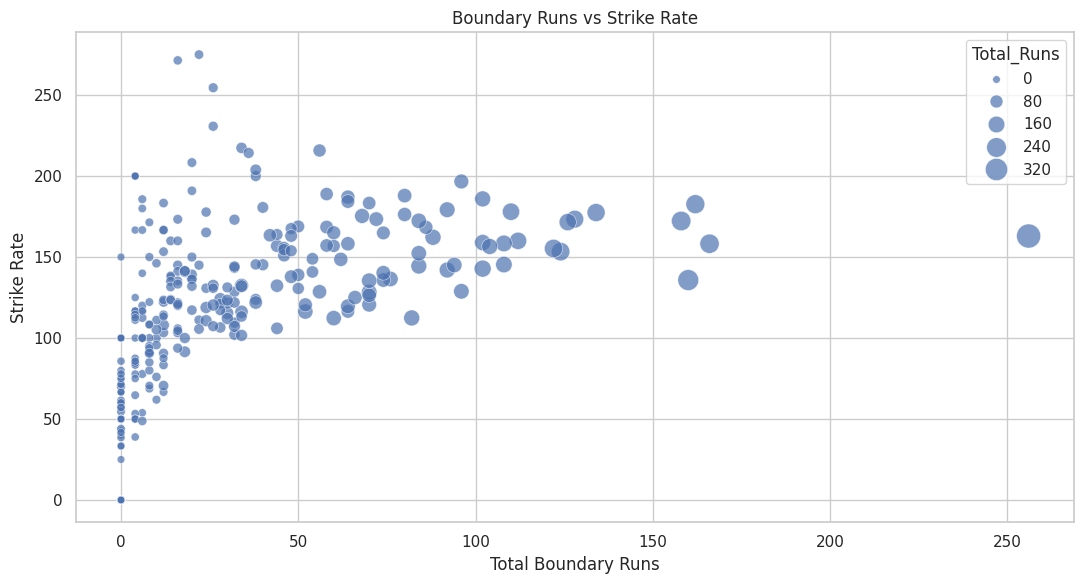

All visualizations generated successfully!


In [18]:
sns.set_theme(style="whitegrid")


# ------------------------------------------
# CHART 1: TOP 10 BATSMEN
# ------------------------------------------

plt.figure(figsize=(12, 6))

plot_data = top_10_batsmen.sort_values("Total_Runs")

sns.barplot(
    data=plot_data,
    x="Total_Runs",
    y="Player"
)

plt.title("Top 10 Batsmen by Total Runs")
plt.xlabel("Total Runs")
plt.ylabel("Player")

plt.tight_layout()
plt.show()


# ------------------------------------------
# CHART 2: TOP 10 BOWLERS
# ------------------------------------------

plt.figure(figsize=(12, 6))

plot_data = top_10_bowlers.sort_values("Total_Wickets")

sns.barplot(
    data=plot_data,
    x="Total_Wickets",
    y="Bowler"
)

plt.title("Top 10 Bowlers by Total Wickets")
plt.xlabel("Total Wickets")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()


# ------------------------------------------
# CHART 3: CHASING VS BATTING FIRST
# ------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=chase_analysis,
    x="Batting_Type",
    y="Average_Runs"
)

plt.title("Average Team Runs: Chasing vs Batting First")
plt.xlabel("Batting Situation")
plt.ylabel("Average Runs")

plt.tight_layout()
plt.show()


# ------------------------------------------
# CHART 4: WIN PERCENTAGE
# ------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=chase_analysis,
    x="Batting_Type",
    y="Win_Percentage"
)

plt.title("Win Percentage: Chasing vs Batting First")
plt.xlabel("Batting Situation")
plt.ylabel("Win Percentage (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------
# CHART 5: TOP 20 PLAYER PERFORMANCE SCORE
# ------------------------------------------

plt.figure(figsize=(13, 7))

plot_data = top_20_pps.sort_values("PPS")

sns.barplot(
    data=plot_data,
    x="PPS",
    y="Player"
)

plt.title("Top 20 Batsmen - Player Performance Score")
plt.xlabel("PPS Score")
plt.ylabel("Player")

plt.tight_layout()
plt.show()


# ------------------------------------------
# CHART 6: TOP 10 ALL-ROUND PERFORMERS
# ------------------------------------------

plt.figure(figsize=(12, 6))

plot_data = top_10_allround.sort_values("MIS")

sns.barplot(
    data=plot_data,
    x="MIS",
    y="Player"
)

plt.title("Top 10 All-Round Performers - Match Impact Score")
plt.xlabel("Match Impact Score")
plt.ylabel("Player")

plt.tight_layout()
plt.show()


# ------------------------------------------
# CHART 7: BOUNDARY RUNS VS STRIKE RATE
# ------------------------------------------

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=player_batting,
    x="Boundary_Runs",
    y="Strike_Rate",
    size="Total_Runs",
    sizes=(30, 300),
    alpha=0.7
)

plt.title("Boundary Runs vs Strike Rate")
plt.xlabel("Total Boundary Runs")
plt.ylabel("Strike Rate")

plt.tight_layout()
plt.show()


print("All visualizations generated successfully!")